<a href="https://colab.research.google.com/github/jppeirce/DSC210-Foundations-of-Data-Science/blob/main/Homework/HW07-supervised_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7 SOLUTIONS: How Many Bikes Tomorrow?

*Instructor version. Do not distribute.*

**DSC 210 Foundations of Data Science**

*Covers Module 11 (supervised learning: regression).*

```
ASK  ->  GET  ->  EXPLORE  ->  [ MODEL ]  ->  COMMUNICATE
```

References:
- Module 11 course notebook (linear regression, MAE / RMSE / $R^2$, residual plots, k-NN and tree regression, random forests, logistic regression, cross-validation)
- Bike sharing data: Fanaee-T, H. and Gama, J. (2013). Event labeling combining ensemble detectors and background knowledge. *Progress in Artificial Intelligence*, 1-15. [doi:10.1007/s13748-013-0040-3](https://doi.org/10.1007/s13748-013-0040-3) (`csv_data/bike_sharing/day.csv`, also used in Homework 3)

*Last major revision: 2026-11-08*

## Key Concepts

- Fit a line, and state its slope and intercept in the units of the problem
- Judge a regression with MAE, RMSE, $R^2$, a baseline, and a residual plot
- Compare a line with k-NN, a tree, and a random forest, and read feature importances
- Predict a probability with logistic regression, and find its decision boundary
- Compare models with cross-validation, and recognize when the order of the rows matters

## Instructions

**Total: 50 points.** Point values are listed with each problem.

- Cells marked `# RUN-TOGETHER` are complete; run them and read the output.
- Cells marked `# FILL-IN` contain blanks written as `____`.
- Cells marked `# ADAPT` are for you to write. Each one names a cell in the **Module 11 notebook**. Find that cell, copy it here, and change it to fit this problem (a different dataset, different columns, different names). Use the variable names the problem asks for, because later cells use them.
- Run the cells **in order**. Every figure must include a title and labeled axes.
- Most of the credit rides on your written answers. Quote specific numbers from your output.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

---
## Part 0. Back at Capital Bikeshare (2 points)
---

In Homework 3 you graphed two years of daily records from Capital Bikeshare in Washington, D.C. Now your manager wants **predictions**: how many bikes will be rented on a given day? Each extra bike on the street costs money, and each customer who finds an empty dock is lost.

You will use these columns (the setup cell converts the first three back into everyday units):

| Column | Meaning |
| --- | --- |
| `temp_c` | temperature (degrees C) |
| `hum_pct` | humidity (%) |
| `wind_kmh` | wind speed (km/h) |
| `yr` | year: 0 for 2011, 1 for 2012 |
| `workingday` | 1 if the day is neither a weekend nor a holiday |
| `weathersit` | 1 clear, 2 mist or clouds, 3 light rain or snow |
| `dteday` | the date |
| `cnt` | **the label:** total bikes rented that day |

In [1]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

bikes = pd.read_csv('https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/csv_data/bike_sharing/day.csv')
bikes['temp_c'] = bikes['temp'] * 41          # the file stores temperature divided by 41
bikes['hum_pct'] = bikes['hum'] * 100
bikes['wind_kmh'] = bikes['windspeed'] * 67

print('shape:', bikes.shape)
bikes[['dteday', 'temp_c', 'hum_pct', 'wind_kmh', 'yr', 'workingday', 'weathersit', 'cnt']].describe().round(1)

shape: (731, 19)


,temp_c,hum_pct,wind_kmh,yr,workingday,weathersit,cnt
count,731.0,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.8,12.8,0.5,0.7,1.4,4504.3
std,7.5,14.2,5.2,0.5,0.5,0.5,1937.2
min,2.4,0.0,1.5,0.0,0.0,1.0,22.0
25%,13.8,52.0,9.0,0.0,0.0,1.0,3152.0
50%,20.4,62.7,12.1,1.0,1.0,1.0,4548.0
75%,26.9,73.0,15.6,1.0,1.0,2.0,5956.0
max,35.3,97.2,34.0,1.0,1.0,3.0,8714.0


**Problem 0.** (2 points)

(a) What does one row of `bikes` represent, and how many are there?

(b) What is the mean number of bikes rented per day? Module 11 says a regression must beat the baseline of "always predict the mean." In one sentence, what would that baseline tell the manager each morning?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) One row is one day of the Capital Bikeshare system: the weather that day, the calendar, and the total number of bikes rented. There are 731 rows, every day of 2011 and 2012.
>
> (b) The mean is about 4,504 bikes per day. The baseline would tell the manager "expect about 4,500 bikes" every single morning, whatever the weather or season. Any model has to do better than that to be useful.

---
## Part A. A line through the data (12 points)
---

### Problem A1. Fit the line (3 points)

**How many more bikes are rented on a warmer day?** Fit a line predicting `cnt` from `temp_c`.

In [2]:
X = bikes[['temp_c']]
y = bikes['cnt']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=210)

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)

print('slope    :', round(lin.coef_[0], 1), 'bikes per degree C')
print('intercept:', round(lin.intercept_, 1), 'bikes')
print('observed temperature range:', round(bikes['temp_c'].min(), 1), 'to', round(bikes['temp_c'].max(), 1), 'degrees C')

slope    : 162.9 bikes per degree C
intercept: 1155.1 bikes
observed temperature range: 2.4 to 35.3 degrees C


(a) Finish the sentence: *"Each additional degree C is associated with ______ more bikes rented per day."*

(b) What does the intercept describe? The coldest day in the data was about 2.4 degrees C. Is the intercept a safe prediction, a mild extrapolation, or a wild one?

(c) The line predicts about 7,680 bikes on a 40 degree C day. Name the problem with trusting that number. (You will see in A3 whether the hottest days really are the busiest.)

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Slope 162.9 bikes per degree C, intercept 1155.1 bikes, observed range 2.4 to 35.3 degrees C.
>
> (a) Each additional degree C is associated with about **163** more bikes rented per day.
>
> (b) The intercept is the predicted number of bikes on a day at 0 degrees C: about 1,155. Zero is just below the coldest day observed (2.4), so it is a **mild** extrapolation, not a wild one; it is plausible but not checked by any data.
>
> (c) 40 degrees C is well above the hottest day in the data (35.3), so this is **extrapolation**: the line keeps climbing forever with no evidence that riders keep coming in extreme heat. (A3 shows the hottest days actually have fewer riders than warm ones.)

### Problem A2. How good is the line? (3 points)

In [3]:
print('MAE :', round(mean_absolute_error(y_test, pred)), 'bikes')
print('RMSE:', round(mean_squared_error(y_test, pred) ** 0.5), 'bikes')
print('R2  :', round(r2_score(y_test, pred), 3))
print()
baseline = np.full_like(y_test, y_train.mean(), dtype=float)
print('baseline MAE (always predict the training mean):', round(mean_absolute_error(y_test, baseline)), 'bikes')

MAE : 1333 bikes
RMSE: 1604 bikes
R2  : 0.337

baseline MAE (always predict the training mean): 1624 bikes


(a) Report MAE, RMSE, $R^2$, and the baseline MAE. By how many bikes per day does the line improve on the baseline?

(b) Module 11 found $R^2 = 0.700$ for mpg from weight. What does this line's $R^2$ say about how much of the day-to-day variation temperature alone explains?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) MAE about **1,333** bikes, RMSE about **1,604** bikes, $R^2$ = **0.337**; the baseline MAE is about **1,624** bikes. The line improves the average miss by about 290 bikes per day.
>
> (b) $R^2 = 0.337$: temperature alone accounts for about a third of the day-to-day variation in rentals, far less than weight did for mpg. Much of what drives rentals must be something else (the year, rain, working days, and so on).

### Problem A3. Read the residuals (3 points)

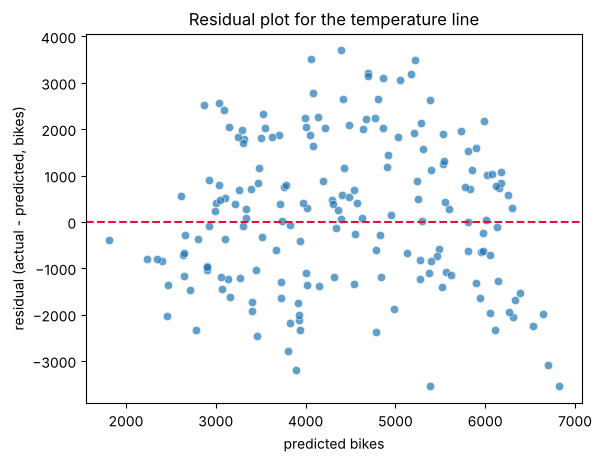

In [4]:
resid = y_test - pred

sns.scatterplot(x=pred, y=resid, alpha=0.7)
plt.axhline(0, color='crimson', linestyle='--')
plt.xlabel('predicted bikes'); plt.ylabel('residual (actual - predicted, bikes)')
plt.title('Residual plot for the temperature line')
plt.show()

In [5]:
# RUN-TOGETHER  (Problem A3): average rentals in temperature bands, all 731 days
bands = pd.cut(bikes['temp_c'], [0, 10, 15, 20, 25, 28, 31, 36])
bikes.groupby(bands, observed=True)['cnt'].agg(['mean', 'count']).round(0)

,mean,count
temp_c,,
"(0, 10]",1678.0,60
"(10, 15]",3264.0,161
"(15, 20]",4192.0,138
"(20, 25]",5577.0,130
"(25, 28]",5586.0,92
"(28, 31]",5857.0,104
"(31, 36]",5217.0,46


(a) Which of the three residual patterns in Module 11, Section 3 does your plot most resemble: no pattern, a curve, or a fan?

(b) Use the temperature-band table to describe the true relationship between temperature and rentals. Where does a straight line go wrong?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) The residuals are not shapeless. (Instructor check, not printed in the notebook:) grouped into thirds by predicted value, they average about +11 bikes for the lowest third of predictions, about +530 for the middle third, and about -53 for the highest third: the middle sits above zero and both ends near or below it. That arch most resembles the **curve** pattern. (The spread is also wide everywhere, so accept "curve" with this evidence; a fan reading needs an argument.)
>
> (b) Rentals climb quickly from cold days (about 1,700 per day below 10 degrees C) to warm days (about 5,600 between 20 and 28 degrees C), then level off (about 5,860 at 28 to 31 degrees C) and **fall** on the hottest days (about 5,200 above 31 degrees C). A straight line has to keep rising, so it under-predicts the warm middle and over-predicts the hottest days.

### Problem A4. Errors by hand (3 points)

Use the rounded line $\hat{y} = 1155 + 163x$ for these four days.

| date | temperature $x$ (degrees C) | actual bikes | predicted | residual |
| --- | --- | --- | --- | --- |
| 2011-01-22 | 2.4 | 981 |  |  |
| 2012-07-04 | 32.4 | 7,403 |  |  |
| 2012-09-15 | 24.9 | 8,714 |  |  |
| 2012-10-29 | 18.0 | 22 |  |  |

(a) Complete the table. Then compute the MAE and the RMSE of these four residuals. (Use Python as a calculator if you like.)

(b) October 29, 2012 fell during Hurricane Sandy; only 22 bikes were rented that day. What share of the **sum of absolute residuals** comes from that one day? What share of the **sum of squared residuals**? Which measure, MAE or RMSE, does one huge miss influence more, and why?

**Your answer:**

(a)

(b)

In [6]:
resid4 = np.array([981 - (1155 + 163 * 2.4), 7403 - (1155 + 163 * 32.4),
                   8714 - (1155 + 163 * 24.9), 22 - (1155 + 163 * 18.0)])
print('residuals:', resid4.round(1))
print('MAE :', round(np.abs(resid4).mean(), 1), '  RMSE:', round(np.sqrt((resid4 ** 2).mean()), 1))
print('without Sandy: MAE', round(np.abs(resid4[:3]).mean(), 1), '  RMSE', round(np.sqrt((resid4[:3] ** 2).mean()), 1))

residuals: [ -565.2   966.8  3500.3 -4067. ]
MAE : 2274.8   RMSE: 2740.7
without Sandy: MAE 1677.4   RMSE 2121.8


> **SOLUTION**
>
> (a)
>
> | date | predicted | residual |
> | --- | --- | --- |
> | 2011-01-22 | 1,546.2 | -565.2 |
> | 2012-07-04 | 6,436.2 | +966.8 |
> | 2012-09-15 | 5,213.7 | +3,500.3 |
> | 2012-10-29 | 4,089.0 | -4,067.0 |
>
> MAE $= (565.2 + 966.8 + 3500.3 + 4067.0)/4 \approx$ **2,274.8** bikes. RMSE $= \sqrt{(565.2^2 + 966.8^2 + 3500.3^2 + 4067.0^2)/4} \approx$ **2,740.7** bikes.
>
> (b) Sum of absolute residuals: 565.2 + 966.8 + 3500.3 + 4067.0 = 9,099.3, of which Sandy contributes 4,067.0, about **45%**. Sum of squares: about 319,000 + 935,000 + 12,252,000 + 16,541,000 = 30,047,000, of which Sandy contributes about **55%**. RMSE squares each miss before averaging, so the largest miss counts for more; RMSE is the measure one huge miss influences more. (Without Sandy, MAE is about 1,677 and RMSE about 2,122.)

---
## Part B. Beyond a straight line (12 points)
---

### Problem B1. Let the model bend (4 points)

A3 showed the relationship is curved. Models that do not assume a line might do better.

In [7]:
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

print(f"{'k':>4}  {'MAE (bikes)':>11}  {'R2':>7}")
for k in (1, 5, 25, 75):
    knn = KNeighborsRegressor(n_neighbors=k).fit(Xtr_s, y_train)
    q = knn.predict(Xte_s)
    print(f'{k:>4}  {mean_absolute_error(y_test, q):>11.0f}  {r2_score(y_test, q):>7.3f}')
print(f"{'line':>4}  {mean_absolute_error(y_test, pred):>11.0f}  {r2_score(y_test, pred):>7.3f}")
print()

for d in (1, 3, None):
    t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_train, y_train)
    print(f'max_depth={str(d):9}  train R2={r2_score(y_train, t.predict(X_train)):.3f}   '
          f'test R2={r2_score(y_test, t.predict(X_test)):.3f}')

   k  MAE (bikes)       R2
   1         1452    0.138
   5         1264    0.367
  25         1247    0.419
  75         1240    0.434
line         1333    0.337

max_depth=1          train R2=0.394   test R2=0.346
max_depth=3          train R2=0.500   test R2=0.396


max_depth=None       train R2=0.869   test R2=0.174


(a) Which k-NN models beat the line on test $R^2$, and by how much? In Module 11 (mpg from weight), k-NN at best only tied the line. Use A3 to explain why bending helps here.

(b) The unlimited tree has the best **training** $R^2$ and the worst **test** $R^2$. Name what happened.

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) k = 25 ($R^2$ 0.419, MAE about 1,247) and k = 75 ($R^2$ 0.434, MAE about 1,240) beat the line ($R^2$ 0.337, MAE about 1,333); k = 5 is about level (0.367) and k = 1 is worse (0.138). The depth-3 tree (test $R^2$ 0.396) also beats the line. Averaging nearby days lets the prediction rise and then level off and dip, following the curve in A3, while the line must keep rising. For mpg the relationship was close to a straight line, so bending had nothing to gain.
>
> (b) **Overfitting**: training $R^2$ 0.869 vs test $R^2$ 0.174. With one feature and no depth limit, the tree builds a step for almost every training day and memorizes day-to-day noise (rain, holidays, the year) that temperature cannot explain.

### Problem B2. More features (4 points)

This is Activity 11.2 with the bike data.

In [8]:
FEATURES = ['temp_c', 'hum_pct', 'wind_kmh', 'yr', 'workingday', 'weathersit']

for label, cols in [('one feature (temperature)', ['temp_c']),
                    ('six features', FEATURES)]:
    Xa, Xb, ya, yb = train_test_split(bikes[cols], bikes['cnt'], test_size=0.25, random_state=210)
    print(f'--- {label} ---')
    for name, model in [('linear', LinearRegression()),
                        ('tree, depth 3', DecisionTreeRegressor(max_depth=3, random_state=0)),
                        ('tree, unlimited', DecisionTreeRegressor(random_state=0)),
                        ('random forest', RandomForestRegressor(n_estimators=200, random_state=0))]:
        model.fit(Xa, ya)
        print(f'  {name:17} train R2={r2_score(ya, model.predict(Xa)):.3f}   '
              f'test R2={r2_score(yb, model.predict(Xb)):.3f}')
    print()

--- one feature (temperature) ---
  linear            train R2=0.412   test R2=0.337


  tree, depth 3     train R2=0.500   test R2=0.396
  tree, unlimited   train R2=0.869   test R2=0.174


  random forest     train R2=0.809   test R2=0.319

--- six features ---
  linear            train R2=0.746   test R2=0.729
  tree, depth 3     train R2=0.778   test R2=0.719
  tree, unlimited   train R2=1.000   test R2=0.605


  random forest     train R2=0.976   test R2=0.815



Use a forest of 200 trees.

(a) With six features, rank the four models by test $R^2$. How much did the best model gain over its one-feature version?

(b) The unlimited tree scores 1.000 on its training days. Is it the best model on the test days? What does the forest do with trees like it?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> Blanks: `FEATURES`, `200`, `predict`.
>
> (a) Six features: random forest **0.815**, linear 0.729, depth-3 tree 0.719, unlimited tree 0.605. The forest's test $R^2$ rose from 0.319 with temperature alone to 0.815, and the line's from 0.337 to 0.729. The extra features, especially the year, carry most of what temperature could not explain.
>
> (b) No: training $R^2$ 1.000 but test $R^2$ 0.605, the worst of the four. The forest grows 200 trees like it, each on a different resample and with random feature subsets, and averages their predictions, which cancels much of the noise each tree memorized (train 0.976, test 0.815).

### Problem B3. What did the forest lean on? (4 points)

Temperature appears in the file twice: `temp` (actual) and `atemp` ("feels like"). Add `atemp` to the six features and see how the forest shares the credit.

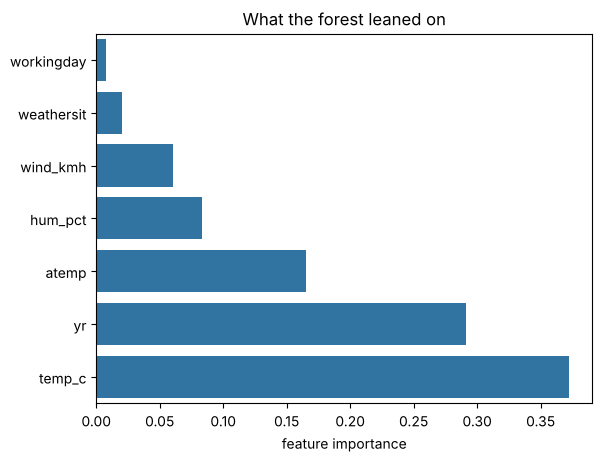

temp_c        0.372
yr            0.291
atemp         0.165
hum_pct       0.083
wind_kmh      0.060
weathersit    0.020
workingday    0.008
dtype: float64


In [9]:
cols7 = FEATURES + ['atemp']
rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(bikes[cols7], bikes['cnt'])

importance = pd.Series(rf.feature_importances_, index=cols7).sort_values()
sns.barplot(x=importance.values, y=importance.index, orient='h')
plt.xlabel('feature importance'); plt.ylabel('')
plt.title('What the forest leaned on')
plt.show()
print(importance.round(3).sort_values(ascending=False))

In [10]:
# RUN-TOGETHER  (Problem B3)
print('correlation of temp and atemp:', round(bikes['temp'].corr(bikes['atemp']), 3))
print()
print('mean bikes per day by year:')
print(bikes.groupby('yr')['cnt'].mean().round(0))

correlation of temp and atemp: 0.992

mean bikes per day by year:
yr
0    3406.0
1    5600.0
Name: cnt, dtype: float64


(a) Which feature is second most important? Use the second cell to explain what that feature is really capturing. Is it about the weather?

(b) Without `atemp`, `temp_c` has an importance of about 0.52. With it, `temp_c` and `atemp` share the credit. Use the correlation to explain why, and what this means for reading importances (Module 11, Section 5.3, Discuss).

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) `yr` (importance about 0.29). Mean rentals rose from about 3,406 per day in 2011 to about 5,600 in 2012. That is growth of the system (more stations, more members, or more awareness, though the data cannot say which), not weather. A model that leans on `yr` has learned that 2012 was busier; it cannot say what 2013 will bring.
>
> (b) With `atemp`, the importances are about 0.37 for `temp_c` and 0.17 for `atemp` (together about 0.54, close to the 0.52 that `temp_c` had alone). The two columns are almost the same information (correlation 0.992), so the trees use whichever happens to be offered at a split, and the credit is divided between them. Importances of correlated features say little about either one on its own; a feature can look minor only because a near-copy took its share.

---
## Part C. Will it be a busy day? (8 points)
---

The manager plans extra staff when more than 5,000 bikes are rented. Call such a day **busy** (1) and any other day **not busy** (0).

### Problem C1. Fit a logistic regression (4 points)

In [11]:
bikes['busy'] = (bikes['cnt'] > 5000).astype(int)
features_c = ['temp_c', 'yr']
Xc, yc = bikes[features_c], bikes['busy']

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, random_state=210, stratify=yc)
log = LogisticRegression(max_iter=2000).fit(Xc_tr, yc_tr)

print('share of busy days:', round(yc.mean(), 3))
print('test accuracy :', round(log.score(Xc_te, yc_te), 3))
print('baseline      :', round(1 - yc.mean(), 3), '(always predict not busy)')
print('intercept     :', round(log.intercept_[0], 2))
for name, coef in zip(features_c, log.coef_[0]):
    print(f'  {name:>7}: {coef:+.2f}')

share of busy days: 0.391
test accuracy : 0.874
baseline      : 0.609 (always predict not busy)
intercept     : -6.76
   temp_c: +0.20
       yr: +3.60


(a) Report the test accuracy and the baseline. How much does the model add?

(b) Both coefficients are positive. Say in words what each sign means for the chance of a busy day.

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) 39.1% of days are busy, so the baseline "always not busy" scores about **0.609** (0.607 on the test days). The model scores **0.874** on the test days, about 27 percentage points better.
>
> (b) `temp_c` (+0.20): warmer days are more likely to be busy. `yr` (about +3.60): at the same temperature, a 2012 day is much more likely to be busy than a 2011 day. (Coefficients are on the $z$ scale, not probabilities; C2 turns them into probabilities.)

### Problem C2. Probabilities and the boundary, by hand (4 points)

Round the model to $z = -6.8 + 0.2\,x + 3.6\,\text{yr}$, where $x$ is the temperature in degrees C, and $p = \dfrac{1}{1 + e^{-z}}$. *(You will need $e^{2.8} \approx 16.44$ and $e^{-0.8} \approx 0.449$.)*

| day | $x$ | yr | $z$ | $p$ (busy) | predicted at 0.5 |
| --- | --- | --- | --- | --- | --- |
| a 20 degree day in 2011 | 20 | 0 |  |  |  |
| a 20 degree day in 2012 | 20 | 1 |  |  |  |

(a) Complete the table.

(b) Find the **decision boundary** temperature for each year: solve $z = 0$ for $x$ with yr = 0, then with yr = 1. Compare each boundary with the temperature range in the data (2.4 to 35.3 degrees C). What does the 2011 boundary say about busy days that year?

(c) The table in A3 showed that the very hottest days are *less* busy. Can this logistic model ever predict a lower probability for a hotter day in the same year? Explain from the formula.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a)
> - 2011, 20 degrees: $z = -6.8 + 0.2(20) + 0 = -2.8$; $p = 1/(1 + e^{2.8}) \approx 1/17.44 \approx 0.057$; predicted **not busy**.
> - 2012, 20 degrees: $z = -6.8 + 4 + 3.6 = 0.8$; $p = 1/(1 + e^{-0.8}) \approx 1/1.449 \approx 0.69$; predicted **busy**.
>
> (b) yr = 0: $-6.8 + 0.2x = 0$ gives $x = 34$ degrees C. yr = 1: $-3.2 + 0.2x = 0$ gives $x = 16$ degrees C. The 2011 boundary sits at the very top of the observed range (the hottest day was 35.3), so in 2011 the model predicts "busy" almost never; in fact only about 10% of 2011 days were busy, against about 69% in 2012. (With the unrounded coefficients the boundaries are about 33.0 and 15.4 degrees C.)
>
> (c) No. $z$ is a straight-line function of $x$ with a positive coefficient, so in a given year $z$ always rises with temperature, and $\sigma$ always rises with $z$. The model cannot capture the dip on the hottest days: logistic regression forces a linear boundary (Module 11 toolkit), and here it also forces the probability to rise steadily with temperature.

---
## Part D. How much should we trust these scores? (10 points)
---

### Problem D1. Folds in date order (5 points)

In [12]:
for f, (train_idx, test_idx) in enumerate(KFold(5).split(X)):
    days = bikes.iloc[test_idx]['dteday']
    print(f'fold {f}: {days.min()} to {days.max()}')

scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print()
print('unshuffled 5-fold R2:', np.round(scores, 3), ' mean:', round(scores.mean(), 3))

kf = KFold(5, shuffle=True, random_state=210)
shuffled = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
print('shuffled 5-fold R2  :', np.round(shuffled, 3), ' mean:', round(shuffled.mean(), 3),
      ' spread:', round(shuffled.max() - shuffled.min(), 3))

fold 0: 2011-01-01 to 2011-05-27
fold 1: 2011-05-28 to 2011-10-20
fold 2: 2011-10-21 to 2012-03-14
fold 3: 2012-03-15 to 2012-08-07
fold 4: 2012-08-08 to 2012-12-31

unshuffled 5-fold R2: [-1.169 -7.42   0.214 -1.582 -0.483]  mean: -2.088
shuffled 5-fold R2  : [0.311 0.416 0.414 0.388 0.43 ]  mean: 0.392  spread: 0.119


(a) The rows are in date order. Which months of which year does fold 1 cover? Its $R^2$ is far below zero. Using B3(a), explain why a line trained on the other four folds predicts that fold so badly. (Hint: which year do most of the *training* days come from, and what was the typical temperature during fold 1?)

(b) With `shuffle=True`, report the five scores, their mean, and their spread.

(c) Module 11 says there is one situation where you should **not** shuffle. Your manager wants to use 2011 and 2012 to forecast the days of **2013**. Should the cross-validation for that job be shuffled? Explain.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a) The folds are consecutive blocks of about five months. Fold 1 covers **2011-05-28 to 2011-10-20**, the warm months of 2011. Unshuffled $R^2$: about -1.17, -7.42, 0.21, -1.58, -0.48 (mean about -2.09). For fold 1, most of the training days (about 63%) come from 2012, when ridership was much higher at the same temperature (B3: about 5,600 vs 3,400 per day). Fold 1's days are almost all warm, so the line predicts high 2012-level counts for them, but they were 2011 days with fewer riders. On top of that, the actual counts in fold 1 vary little around their own mean, so even a moderate systematic miss produces a large negative $R^2$.
>
> (b) Shuffled: about 0.311, 0.416, 0.414, 0.388, 0.430; mean about **0.392**, spread about 0.12.
>
> (c) **No.** Forecasting 2013 means predicting days that come *after* all the training data. Shuffled folds let the model train on days on both sides of each test day, which is easier than the real job, so the score would be optimistic. The honest check is to train on earlier days and test on later ones (for example, train on 2011 and test on 2012), which is closer to what the unshuffled folds do.

### Problem D2. Choose a model honestly (5 points)

Module 11, Section 7.2 compares models with cross-validation. Here, keep a **test set** aside, run the cross-validation on the **training** days only, choose one model, and only then score it once on the test set.

In [13]:
X6_train, X6_test, y6_train, y6_test = train_test_split(bikes[FEATURES], bikes['cnt'],
                                                        test_size=0.25, random_state=210)
kf = KFold(5, shuffle=True, random_state=210)

for name, model in [('linear regression', LinearRegression()),
                    ('tree, depth 3', DecisionTreeRegressor(max_depth=3, random_state=0)),
                    ('random forest', RandomForestRegressor(n_estimators=200, random_state=0))]:
    s = cross_val_score(model, X6_train, y6_train, cv=kf, scoring='r2')
    print(f'{name:>18}:  mean R2 = {s.mean():.3f}   folds {np.round(s, 3)}')

final = RandomForestRegressor(n_estimators=200, random_state=0).fit(X6_train, y6_train)
final_pred = final.predict(X6_test)
print()
print('chosen model on the test days:  R2 =', round(r2_score(y6_test, final_pred), 3),
      '  MAE =', round(mean_absolute_error(y6_test, final_pred)), 'bikes')

 linear regression:  mean R2 = 0.731   folds [0.722 0.739 0.746 0.724 0.724]
     tree, depth 3:  mean R2 = 0.727   folds [0.744 0.682 0.765 0.72  0.722]


     random forest:  mean R2 = 0.810   folds [0.818 0.784 0.821 0.823 0.805]



chosen model on the test days:  R2 = 0.815   MAE = 677 bikes


(a) Which model has the best mean cross-validated $R^2$? Is the gap between the top two larger than the spread of their fold scores?

(b) Report your chosen model's test $R^2$ and MAE. Why is this single test number more trustworthy than if you had tried all three models on the test set and reported the best?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> (a) Random forest, mean $R^2$ about **0.810** (folds 0.784 to 0.823), against linear regression 0.731 (folds 0.722 to 0.746) and the depth-3 tree 0.727 (folds 0.682 to 0.765). The forest's gap over the line (about 0.08) is larger than either model's fold spread (about 0.04 and 0.02), and every forest fold beats every linear fold, so the advantage looks real rather than luck.
>
> (b) Test $R^2$ about **0.815**, MAE about **677** bikes per day. The test days played no part in choosing the model, so the score estimates performance on new days. Trying all three on the test set and keeping the best would let the test set influence the choice, and the reported number would be optimistic (Module 10, Section 2).

---
## Part E. Review and report (6 points)
---

### Problem E1. Code review: four quiet bugs (4 points)

A teammate wrote the cell below. **Every line runs.** For each numbered line, say what is wrong and how the output could give it away, then write a corrected version.

In [14]:
# RUN-TOGETHER  (a teammate's code: it runs, but every line has a problem)

# 1. R2 of the temperature line
print('1. R2:', round(r2_score(pred, y_test), 3))

# 2. RMSE of the temperature line
print('2. RMSE:', round(mean_squared_error(y_test, pred)), 'bikes')

# 3. How many more bikes per degree C?
lin_3 = LinearRegression().fit(bikes.loc[X_train.index, ['temp']], y_train)
print('3. bikes per degree C:', round(lin_3.coef_[0], 1))

# 4. How well will the forest do on new days?
print('4. forest R2 on new days:', round(r2_score(y6_train, final.predict(X6_train)), 3))

1. R2: -0.846
2. RMSE: 2572875 bikes
3. bikes per degree C: 6678.8
4. forest R2 on new days: 0.976


**Your answer:**

| Line | What is wrong | How the output gives it away |
| --- | --- | --- |
| 1 |  |  |
| 2 |  |  |
| 3 |  |  |
| 4 |  |  |

In [15]:
print('1.', round(r2_score(y_test, pred), 3))
print('2.', round(mean_squared_error(y_test, pred) ** 0.5), 'bikes')
print('3.', round(LinearRegression().fit(X_train, y_train).coef_[0], 1))      # use temp_c, in degrees C
print('4.', round(r2_score(y6_test, final.predict(X6_test)), 3))

1. 0.337
2. 1604 bikes
3. 162.9
4. 0.815


> **SOLUTION**
>
> | Line | What is wrong | How the output gives it away |
> | --- | --- | --- |
> | 1 | The arguments are reversed: `r2_score` expects the actual values first. $R^2$ compares against the mean of the first argument, so swapping them changes the answer. | It prints -0.846, but A2 found 0.337 for the same predictions. |
> | 2 | That is the MSE, not the RMSE: the square root is missing. | 2,572,875 "bikes" is larger than any day's total; MSE is in bikes squared. |
> | 3 | It uses `temp`, which the file stores divided by 41, so the slope is per 41 degrees C. | 6,678.8 bikes per degree is absurd; it is 41 times the A1 slope (162.9). |
> | 4 | It scores the forest on its **training** days, which measures memory, not new days. | 0.976 is much higher than the cross-validated 0.810 and the test 0.815. |

### Problem E2. Report to the manager (2 points)

In 3 to 4 sentences for a manager who has never fit a model: which model would you use to plan bikes for tomorrow, how far off should she expect it to be on a typical day (in bikes), and one caution about using it next year.

**Your answer:**

> **SOLUTION**
>
> Sample answer. Use the random forest built on temperature, humidity, wind, year, working day, and weather type. On days it had not seen, it was off by about 680 bikes on a typical day, compared with about 1,620 for simply guessing the average, and it explained about 80% of the day-to-day variation in cross-validation. It cannot foresee unusual days: on October 29, 2012, during Hurricane Sandy, only 22 bikes were rented. And because ridership grew so much from 2011 to 2012, the model's sense of a "normal" day comes from those two years; if growth continued, it would likely under-predict 2013.